# Reading ADCIRC grids with `pyramids-mesh`

[ADCIRC](https://adcirc.org/) is a coastal-ocean circulation and storm-surge model. Its mesh lives in a plain-text **`fort.14`** grid file: a header, then one line per node (`id lon lat depth`), then one line per triangular element (`id n a b c`), then open- and land-boundary sections. Water-surface results (`zeta`) are written to a companion NetCDF **`fort.63.nc`**.

`pyramids-mesh` registers an `adcirc` **driver** whose only job is to parse those files and hand back a `pyramids.netcdf.ugrid.UgridDataset` wrapping a `Mesh2d`. Once the grid is a pyramids object, the whole pyramids GIS toolbox applies — bounds, CRS handling, `GeoDataFrame` conversion, bounding polygons, plotting through cleopatra. This notebook reads the public-domain **Shinnecock Inlet** example and works through read → explore → plot → GIS.

## 1. Pin the plotting backend

Figures are rendered through `cleopatra` (matplotlib). So the notebook runs identically under
CI and interactively, we pin the non-interactive **`Agg`** backend *before* importing `pyplot`,
and define a tiny `show()` helper that grabs the current figure, saves it to an in-memory PNG and
embeds it inline. With `Agg` a bare `plt.show()` embeds nothing, so every plot below ends with a
`show()` call instead.

In [1]:
import os
os.environ["MPLBACKEND"] = "Agg"
import matplotlib; matplotlib.use("Agg")
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Image, display
def show():
    from io import BytesIO
    buf = BytesIO(); plt.gcf().savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close("all"); buf.seek(0); display(Image(data=buf.read()))

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [2]:
from pyramids.netcdf.ugrid import UgridDataset
import numpy as np
from pathlib import Path

## 3. Locate the data

This notebook lives in `docs/examples/`, so the repo-root `examples/data/` folder is two levels up. Paths inside a notebook are always written relative to the notebook itself. The ADCIRC folder holds the `fort.14` grid and the `fort.63.nc` result file. We pass a `pathlib.Path` to the reader — never a string.

In [3]:
DATA = Path("../../examples/data")
grid = DATA / "adcirc" / "fort.14"
sorted(p.name for p in (DATA / "adcirc").iterdir())

['SOURCE.txt', 'fort.14', 'fort.63.nc']

`fort.14` is the grid; `fort.63.nc` carries the time-varying surface elevation. The `adcirc` driver reads the grid and, when the `fort.63.nc` companion sits beside it, pulls its `zeta` results in automatically — so one `read_file` call gives us both geometry and data.

## 4. Read the grid

`UgridDataset.read_file` dispatches on the driver we name. We pass `driver="adcirc"` explicitly; the returned object is a `UgridDataset`. (The reader may warn that it reversed some clockwise faces to counter-clockwise — that is the UGRID winding convention being enforced, not an error.)

In [4]:
ds = UgridDataset.read_file(grid, driver="adcirc")
ds

UgridDataset(mesh='mesh2d', n_node=3070, n_face=5780, n_edge=0, variables=['zeta', 'node_z'])

## 5. Explore the mesh

A handful of properties describe the grid: node and face counts, the coordinate reference system, the data variables the driver attached, and the bounding box. ADCIRC grids store longitude/latitude, but `fort.14` declares **no CRS**, so `crs` / `epsg` come back `None` — we treat the coordinates as geographic degrees but pyramids will not assume so.

In [5]:
{"n_node": ds.n_node, "n_face": ds.n_face,
 "epsg": ds.epsg, "crs": ds.crs,
 "variables": ds.data_variable_names,
 "bounds": tuple(round(b, 3) for b in ds.bounds)}

{'n_node': 3070,
 'n_face': 5780,
 'epsg': None,
 'crs': None,
 'variables': ['zeta', 'node_z'],
 'bounds': (-72.924, 40.384, -72.033, 40.99)}

3070 nodes, 5780 triangles, bounds around 72.9–72.0°W / 40.4–41.0°N (Long Island, NY). Two variables rode in with the grid: `node_z` (sea-bed depth, per node) and `zeta` (surface elevation). `summary()` tabulates each variable's statistics — note `zeta` has far more values than there are nodes because it is **time-varying**.

In [6]:
ds.summary()

,count,min,max,mean,std
variable,,,,,
zeta,173936,-0.587433,0.627106,0.014328,0.338818
node_z,3070,-2.342191,57.560005,27.422450,16.496160


## 6. Mesh geometry

The `Mesh2d` behind the dataset exposes the raw topology: node coordinates, the `(n_face, 3)` face-node connectivity table (each triangle's three node indices), per-face areas and centroids. These are plain numpy arrays.

In [7]:
m = ds.mesh
fnc = np.asarray(m.face_node_connectivity.data)
cen = np.asarray(m.face_centroids)
{"fnc_shape": fnc.shape, "first_triangle": fnc[0].tolist(),
 "centroids_shape": cen.shape,
 "mean_face_area": float(np.asarray(m.face_areas).mean())}

{'fnc_shape': (5780, 3),
 'first_triangle': [76, 75, 0],
 'centroids_shape': (2, 5780),
 'mean_face_area': 5.783217365792851e-05}

The connectivity is `(5780, 3)` — every element is a triangle. Centroids come back as `(2, n_face)` (x-row, y-row). The mean face area is in squared degrees here because the coordinates are geographic; on a projected grid it would be m².

## 7. Wireframe

`plot_outline()` draws the mesh skeleton — every element edge, no data colouring. It is the quickest way to see the grid's shape and where it is refined. Shinnecock Inlet's mesh is far denser around the inlet channel than offshore.

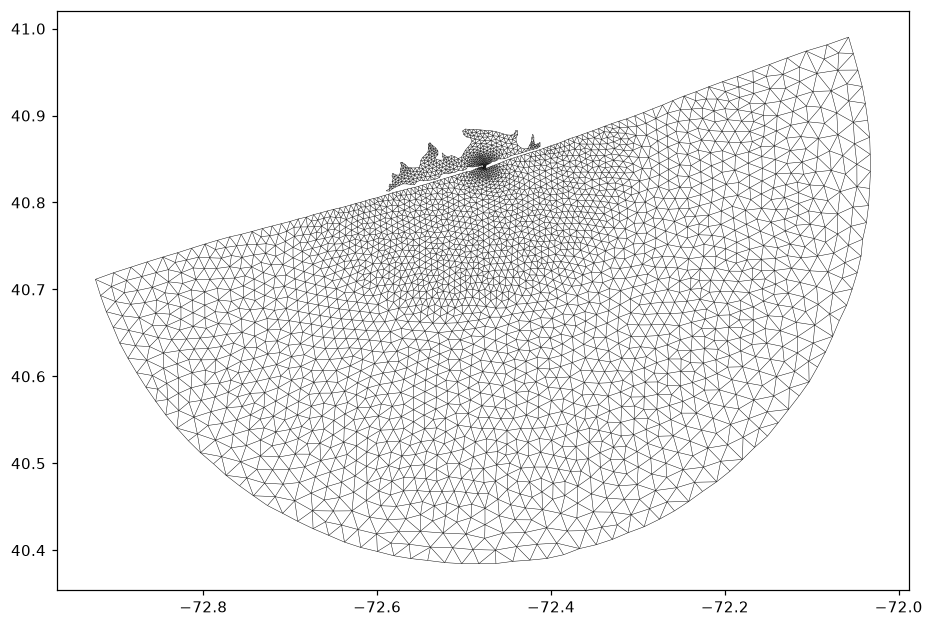

In [8]:
ds.plot_outline(); show()

## 8. Data map — surface elevation

`plot(variable)` colours each element by a data variable. `zeta` is time-varying `(57 steps, 3070 nodes)`; the mesh renderer draws the **first time step**. This is the modelled sea-surface elevation across the domain at the start of the run.

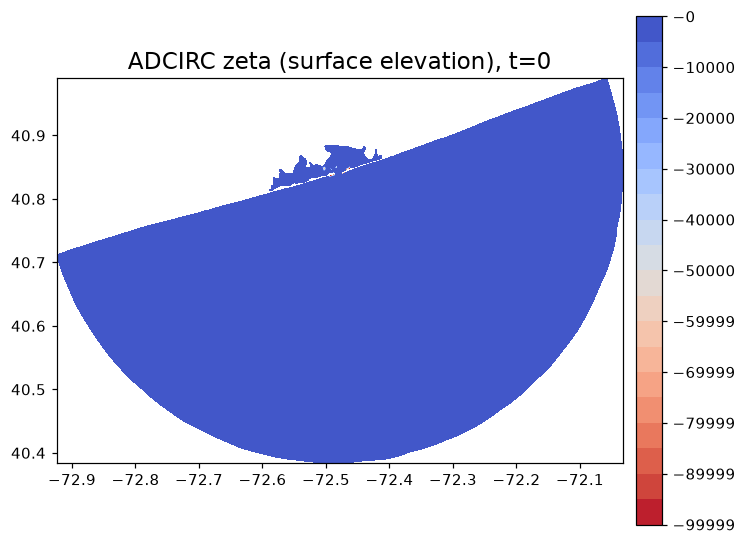

In [9]:
ds.plot("zeta", cmap="viridis", colorbar=True,
        title="ADCIRC zeta (surface elevation), t=0"); show()

And the static sea-bed depth, `node_z`, on a terrain colormap — shallow over the barrier and inlet, deepening offshore.

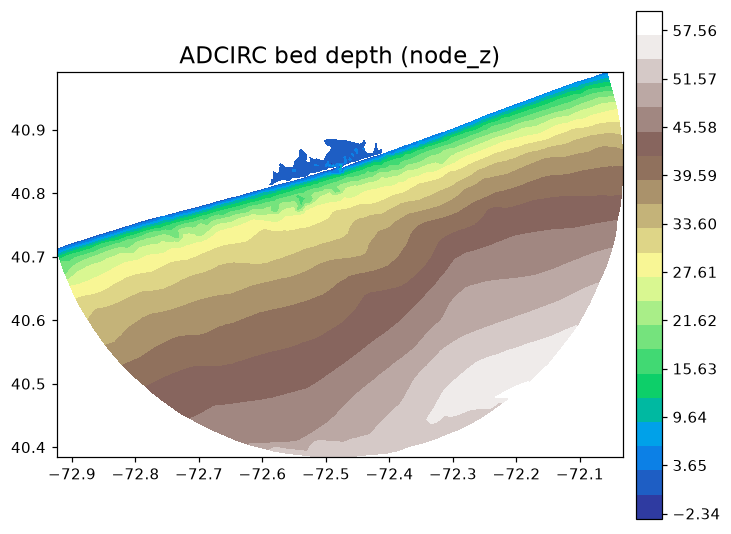

In [10]:
ds.plot("node_z", cmap="terrain", colorbar=True,
        title="ADCIRC bed depth (node_z)"); show()

## 9. GIS operations for free

Because the grid is a pyramids object, pyramids' vector/GIS layer applies unchanged. First, convert to a GeoDataFrame — one polygon per element, ready for geopandas, spatial joins or export. `to_geodataframe()` returns just the geometry column, so we attach each element's **area** and let geopandas colour by it — the small cells pick out the refined inlet.

In [11]:
gdf = ds.to_geodataframe()
gdf["face_area"] = np.asarray(ds.mesh.face_areas)
gdf.head()

,geometry,face_area
0,"POLYGON ((-72.08262 40.98137, -72.0691 40.9720...",0.000176
1,"POLYGON ((-72.0691 40.97205, -72.05219 40.9713...",0.000158
2,"POLYGON ((-72.07002 40.95222, -72.05219 40.971...",0.000168
3,"POLYGON ((-72.05219 40.97134, -72.07002 40.952...",0.000219
4,"POLYGON ((-72.04697 40.95238, -72.07002 40.952...",0.000182


Each row is one triangle. Colouring by `face_area` with geopandas highlights the refinement: the tiny cells cluster around the inlet, the large ones sit offshore.

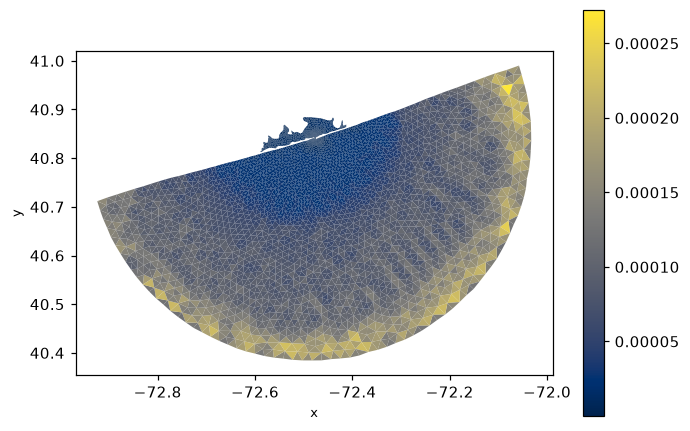

In [12]:
gdf.plot(column="face_area", cmap="cividis", figsize=(7, 5),
         legend=True); show()

The **bounding polygon** is the dissolved outer hull of the mesh — its true (non-rectangular) footprint. We draw it over the wireframe.

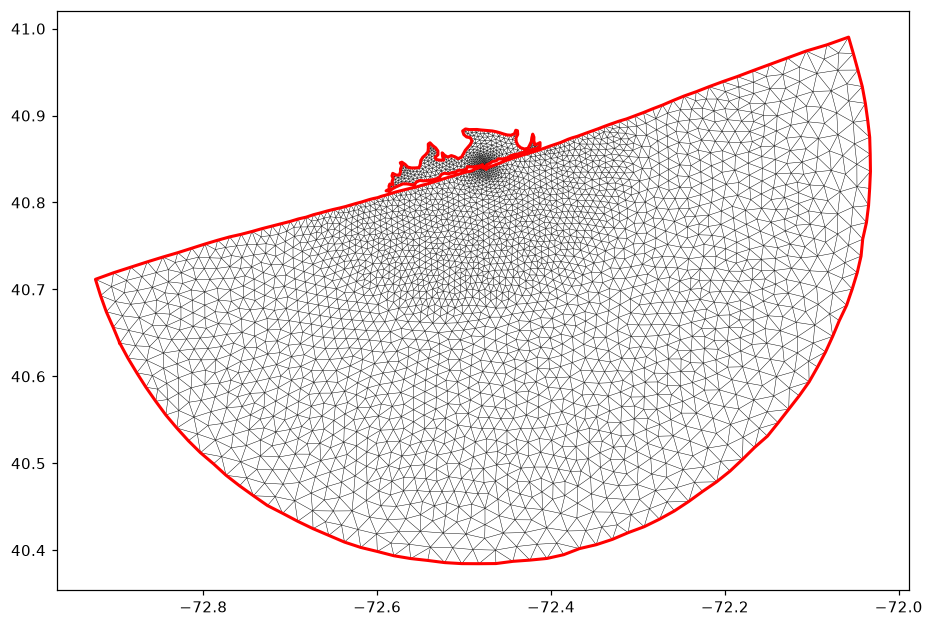

In [13]:
poly = ds.bounding_polygon()
ax = ds.plot_outline().ax
xs, ys = poly.exterior.xy
ax.plot(xs, ys, color="red", lw=2); show()

`exterior_edges()` returns the boundary edges — the shoreline plus open-ocean rim of this grid. Here is how many there are.

In [14]:
ext = ds.exterior_edges()
{"exterior_edge_rows": int(np.asarray(ext).shape[0])}

{'exterior_edge_rows': 358}

**Connectivity / connected components.** `sparse_adjacency()` returns the node-node adjacency as a SciPy sparse matrix; `connected_components()` labels each node's component. A single component (all one label) means the grid is one unbroken sheet — exactly what a valid circulation mesh should be.

In [15]:
adj = ds.sparse_adjacency()
comp = ds.connected_components()
{"adjacency_shape": adj.shape, "nnz": int(adj.nnz),
 "n_components": int(np.unique(comp).size)}

{'adjacency_shape': (5780, 5780), 'nnz': 16982, 'n_components': 1}

**Spatial subset.** `subset_by_bounds` keeps only the faces whose extent falls inside a box — here a window on the inlet itself. The result is a smaller, self-consistent `UgridDataset` with its connectivity renumbered.

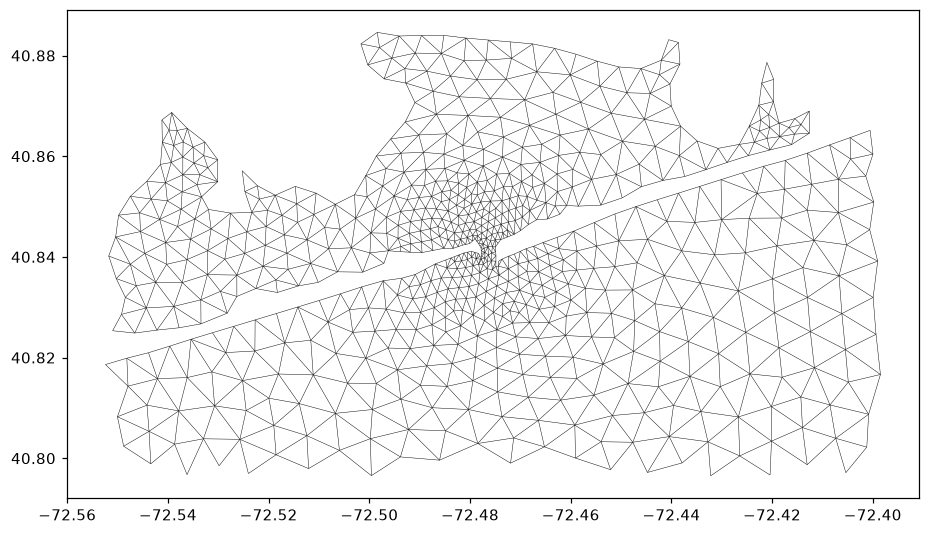

In [16]:
inlet = ds.subset_by_bounds(-72.55, 40.80, -72.40, 40.92)
inlet.plot_outline(); show()

The window keeps only the faces inside the box — a fraction of the full grid:

In [17]:
{"faces_kept": inlet.n_face, "of_total": ds.n_face}

{'faces_kept': 1223, 'of_total': 5780}

**Export.** `to_file` writes the mesh back out through any writer driver — here to an SMS `2dm` grid in a temp folder.

In [18]:
import tempfile
out = Path(tempfile.gettempdir()) / "shinnecock.2dm"
ds.to_file(out, driver="2dm")
{"written": out.name, "exists": out.exists()}

{'written': 'shinnecock.2dm', 'exists': True}

And `to_xarray()` hands the whole thing — mesh plus variables — to the xarray ecosystem for further analysis.

In [19]:
xds = ds.to_xarray()
type(xds).__name__, list(xds.data_vars)

('Dataset',
 ['mesh2d',
  'mesh2d_node_x',
  'mesh2d_node_y',
  'mesh2d_face_nodes',
  'zeta',
  'node_z'])

## 10. What needs more than a grid

Two families of operation are **deliberately skipped** here:

- **`to_crs(epsg)`** reprojects coordinates, but it needs a *source* CRS. `fort.14` declares none, so `ds.epsg is None` and `to_crs` raises `Cannot reproject: source CRS is unknown`. The coordinates are lon/lat (EPSG:4326) by convention, but the file does not say so, so pyramids will not guess.
- **`rasterize_like` / `regrid`** need a *reference grid* to sample onto; with only the mesh in hand there is nothing to target, so they are out of scope for this read-only tour.

## Takeaway

`UgridDataset.read_file(path, driver="adcirc")` turns a `fort.14` grid (plus its `fort.63.nc` results) into a first-class pyramids mesh. From there, exploration, plotting, GeoDataFrame conversion, bounding polygons, connectivity analysis, spatial subsetting and export are all inherited from pyramids — `pyramids-mesh` only added the *reader*.